In [13]:
# ==============================
# Notebook: Parikshit_LC_Borrower_Insights.ipynb
# Author: Parikshit Narang
# Purpose: Lending Club Borrower Analysis (Using preprocessed dataset)
# Features: Borrower segmentation, behavioral analysis, geographic insights, cluster visualization
# ==============================

# ------------------------------
# 1. Import Libraries
# ------------------------------
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, month, year, avg, sum as Fsum, months_between, current_date
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder
from pyspark.ml.clustering import KMeans
from pyspark.ml import Pipeline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# ------------------------------
# 2. Initialize Spark Session
# ------------------------------
spark = SparkSession.builder \
    .appName("Parikshit_LC_Borrower_Insights") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "16g") \
    .getOrCreate()

25/11/21 00:56:47 WARN Utils: Your hostname, Parikshits-MacBook-Pro-6.local resolves to a loopback address: 127.0.0.1; using 10.0.0.55 instead (on interface en0)
25/11/21 00:56:47 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


25/11/21 00:56:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
# ------------------------------
# 3. Load Preprocessed Dataset
# ------------------------------
processed_path = "../dataset/processed"
df = spark.read.parquet(processed_path)

# Cast problematic string columns to numeric
numeric_cols = ["revol_util", "dti", "delinq_2yrs", "annual_inc"]
for c in numeric_cols:
    df = df.withColumn(c, col(c).cast("double"))

print(f"Loaded preprocessed dataset with {df.count()} rows and {len(df.columns)} columns.")
df.show(5)



Loaded preprocessed dataset with 1000 rows and 146 columns.
25/11/21 00:56:51 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
+----+---------+---------+-----------+---------------+----+--------+-----------+-----+---------+--------------+----------+--------------+----------+-------------------+----------+-----------+----------+----+----+------------------+------------------+--------+----------+-----+-----------+----------------+--------------+----------------------+----------------------+--------+-------+---------+----------+---------+-------------------+---------+-------------+-----------+---------------+---------------+-------------+------------------+----------+-----------------------+------------+---------------+------------+------------------+--------------------------+---------------------------+-----------+----------------+----------------+---------+------------------

In [4]:
# ------------------------------
# 4. Feature Selection for Clustering
# ------------------------------
# We'll use key numeric features and optionally encode categorical features
numeric_features = ["revol_util", "dti", "total_bal_ex_mort", "num_accts_ever_120_pd", "delinq_2yrs", "annual_inc"]
categorical_features = ["home_ownership", "purpose", "grade", "sub_grade", "term", "verification_status"]

# Index + OneHotEncode categorical columns
indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in categorical_features]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_vec") for c in categorical_features]

# Assemble features
assembler = VectorAssembler(
    inputCols=numeric_features + [c+"_vec" for c in categorical_features],
    outputCol="features"
)

# Scale features
scaler = StandardScaler(inputCol="features", outputCol="scaledFeatures")

In [5]:
# ------------------------------
# 5. K-Means Clustering
# ------------------------------
kmeans = KMeans(featuresCol="scaledFeatures", k=5, seed=42, predictionCol="cluster")

# Full pipeline
pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler, kmeans])
model = pipeline.fit(df)
df_clusters = model.transform(df)

25/11/21 00:56:54 WARN InstanceBuilder$JavaBLAS: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


In [6]:
# ------------------------------
# 6. Cluster Profiling
# ------------------------------
cluster_stats = df_clusters.groupBy("cluster").agg(
    avg("revol_util").alias("avg_revol_util"),
    avg("dti").alias("avg_dti"),
    avg("total_bal_ex_mort").alias("avg_total_bal_ex_mort"),
    avg("num_accts_ever_120_pd").alias("avg_num_120_pd"),
    avg("delinq_2yrs").alias("avg_delinq_2yrs"),
    avg("annual_inc").alias("avg_annual_inc")
).orderBy("cluster")

print("Cluster Profiles:")
cluster_stats.show()

Cluster Profiles:
+-------+------------------+------------------+---------------------+-------------------+-------------------+------------------+
|cluster|    avg_revol_util|           avg_dti|avg_total_bal_ex_mort|     avg_num_120_pd|    avg_delinq_2yrs|    avg_annual_inc|
+-------+------------------+------------------+---------------------+-------------------+-------------------+------------------+
|      0| 49.65510204081634|20.321428571428577|    60027.22448979592|                0.6| 0.3306122448979592| 84349.08571428571|
|      1|56.766666666666666| 26.60466666666667|              75192.2| 0.4666666666666667|0.26666666666666666| 79977.33333333333|
|      2|32.583333333333336|17.091666666666665|   46096.333333333336| 0.8333333333333334| 0.6666666666666666|60283.333333333336|
|      3| 41.63361344537816|18.963515406162472|   59035.899159663866|0.44537815126050423|0.15126050420168066| 85903.05042016807|
|      4|            52.225|18.642999999999997|             49936.65|          

In [7]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.functions import year, month

# Step 1: convert earliest_cr_line to a proper date
df_clusters = df_clusters.withColumn(
    "earliest_cr_line_dt",
    F.to_date(F.concat(F.lit("01-"), F.col("earliest_cr_line")), "dd-MMM-yyyy")
)

# Step 2: Group by year and month and calculate average delinquencies
default_trends = df_clusters.groupBy(
    year("earliest_cr_line_dt").alias("year"),
    month("earliest_cr_line_dt").alias("month")
).agg(
    F.avg("delinq_2yrs").alias("avg_delinquencies")
).orderBy("year", "month")

default_trends.show(50)


+----+-----+-----------------+
|year|month|avg_delinquencies|
+----+-----+-----------------+
|1970|    6|              0.0|
|1972|    8|              0.0|
|1972|   12|              0.0|
|1973|    5|              0.0|
|1974|    3|              1.0|
|1975|    5|              0.0|
|1978|    4|              0.0|
|1978|   11|              0.0|
|1979|    3|              0.0|
|1979|    6|              1.0|
|1980|    1|              4.0|
|1981|    6|              0.0|
|1982|    2|              0.0|
|1982|    6|              0.5|
|1982|   11|              1.0|
|1983|    7|              0.0|
|1983|   11|              0.5|
|1984|    4|              0.0|
|1984|    5|              0.0|
|1984|    9|              0.0|
|1984|   11|              0.5|
|1985|    2|              0.0|
|1985|    5|              1.0|
|1985|    8|              0.0|
|1985|    9|              0.0|
|1985|   10|              0.0|
|1986|    4|              1.0|
|1986|    6|              0.0|
|1986|    7|              0.0|
|1986|  

In [8]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.functions import year, month

df_clusters = df_clusters.withColumn(
    "earliest_cr_line_dt",
    F.to_date(F.concat(F.lit("01-"), F.col("earliest_cr_line")), "dd-MMM-yyyy")
)

windowSpec = Window.orderBy("earliest_cr_line_dt").rowsBetween(-5, 0)  # last 6 months including current

df_clusters = df_clusters.withColumn(
    "rolling_avg_delinq",
    F.avg("delinq_2yrs").over(windowSpec)
)

default_trends = df_clusters.groupBy(
    year("earliest_cr_line_dt").alias("year"),
    month("earliest_cr_line_dt").alias("month")
).agg(
    F.avg("rolling_avg_delinq").alias("rolling_avg_delinquencies")
).orderBy("year", "month")

default_trends.show(50)


25/11/21 00:56:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/11/21 00:56:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/11/21 00:56:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/11/21 00:56:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
+----+-----+-------------------------+
|year|month|rolling_avg_delinquencies|
+----+-----+-------------------------+
|1970|    6|                      0.0|
|1972|    8|                      0.0|
|1972|   12|                      0.0|
|1973|    5|                      0.0|
|1974|    3|                      0.2|
|1975|    5|      0.16666666

In [9]:
# ------------------------------
# 8. Geographic & Demographic Insights
# ------------------------------
# Default & income by state
state_stats = df_clusters.groupBy("addr_state").agg(
    avg("dti").alias("avg_dti"),
    avg("annual_inc").alias("avg_income"),
    avg("acc_now_delinq").alias("avg_delinq"),
    Fsum("loan_amnt").alias("total_loans")
).orderBy("addr_state")
state_stats.show()

# Home ownership vs income verification
demo_stats = df_clusters.groupBy("home_ownership", "verification_status").agg(
    avg("acc_now_delinq").alias("avg_delinq"),
    avg("annual_inc").alias("avg_income")
)
demo_stats.show()

+----------+------------------+------------------+----------+-----------+
|addr_state|           avg_dti|        avg_income|avg_delinq|total_loans|
+----------+------------------+------------------+----------+-----------+
|        AL| 25.14909090909091| 71036.36363636363|       0.0|     160125|
|        AR|22.994999999999997|           63175.0|       0.0|      37400|
|        AZ|           19.7412|           72288.2|       0.0|     427725|
|        CA|19.294358974358975| 81370.69230769231|       0.0|    1961175|
|        CO|16.819999999999997|       101063.8125|       0.0|     242400|
|        CT|             20.24|         98229.125|       0.0|     219700|
|        DC|              12.3|          100203.0|       0.0|      18000|
|        DE|14.040000000000001|           58450.0|       0.0|      26200|
|        FL| 19.19885714285715| 76476.25714285714|       0.0|    1018975|
|        GA|18.193181818181817| 84123.31818181818|       0.0|     772300|
|        HI|             8.475|       

Columns available for plotting: ['cluster', 'revol_util', 'dti', 'total_bal_ex_mort', 'num_accts_ever_120_pd', 'delinq_2yrs', 'annual_inc', 'home_ownership_vec_0', 'home_ownership_vec_1', 'home_ownership_vec_2', 'home_ownership_vec_3', 'purpose_vec_0', 'purpose_vec_1', 'purpose_vec_2', 'purpose_vec_3', 'purpose_vec_4', 'purpose_vec_5', 'purpose_vec_6', 'purpose_vec_7', 'purpose_vec_8', 'purpose_vec_9', 'purpose_vec_10', 'purpose_vec_11', 'grade_vec_0', 'grade_vec_1', 'grade_vec_2', 'grade_vec_3', 'grade_vec_4', 'grade_vec_5', 'sub_grade_vec_0', 'sub_grade_vec_1', 'sub_grade_vec_2', 'sub_grade_vec_3', 'sub_grade_vec_4', 'sub_grade_vec_5', 'sub_grade_vec_6', 'sub_grade_vec_7', 'sub_grade_vec_8', 'sub_grade_vec_9', 'sub_grade_vec_10', 'sub_grade_vec_11', 'sub_grade_vec_12', 'sub_grade_vec_13', 'sub_grade_vec_14', 'sub_grade_vec_15', 'sub_grade_vec_16', 'sub_grade_vec_17', 'sub_grade_vec_18', 'sub_grade_vec_19', 'sub_grade_vec_20', 'sub_grade_vec_21', 'sub_grade_vec_22', 'sub_grade_vec_23'

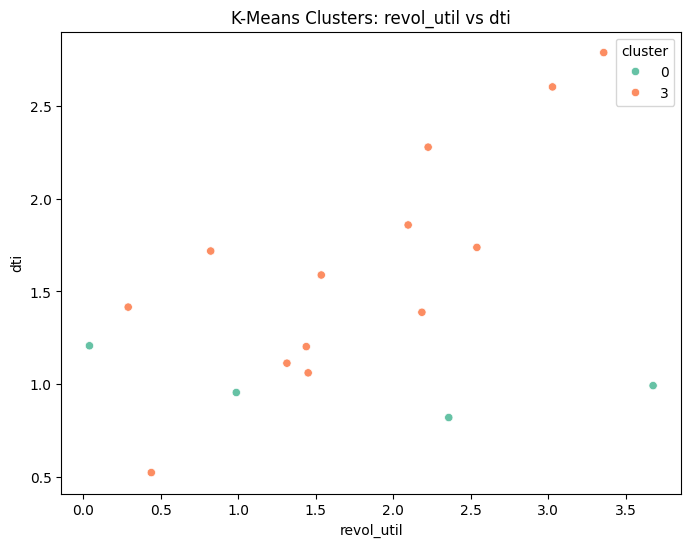

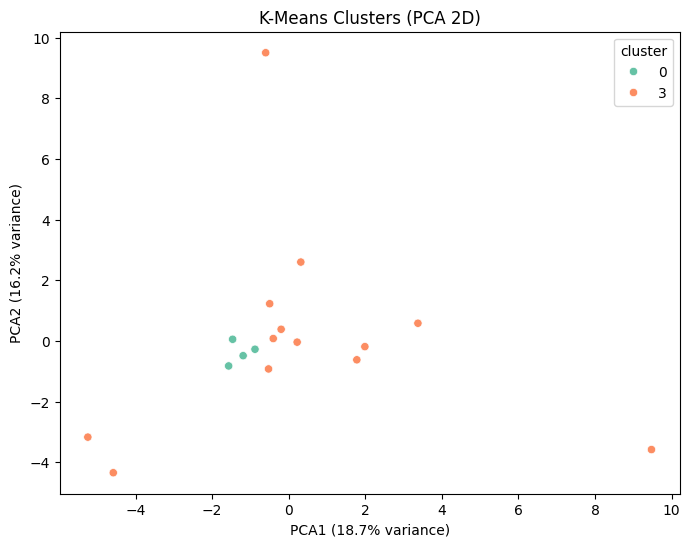

Feature contributions to PCA components:


,PC1,PC2
purpose_vec_7,6.449190e-01,-2.807368e-01
sub_grade_vec_5,4.276784e-01,-1.127216e-01
grade_vec_0,2.241819e-01,-1.298879e-02
purpose_vec_4,1.499022e-01,2.992852e-02
home_ownership_vec_0,1.494510e-01,1.316833e-01
verification_status_vec_0,1.101569e-01,-8.321577e-02
term_vec_1,4.345813e-02,1.419139e-01
num_accts_ever_120_pd,3.400620e-02,-1.970932e-02
total_bal_ex_mort,2.134916e-02,4.875355e-01
dti,1.821014e-02,4.680697e-02


In [10]:
# ------------------------------
# Cluster Visualization with Proper Feature Names
# ------------------------------

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# ------------------------------
# 1. Sample 2% of data for plotting
# ------------------------------
sample_df = df_clusters.select("scaledFeatures", "cluster").sample(fraction=0.02, seed=42).toPandas()

# Convert SparseVector/DenseVector to dense array
sample_df['scaledFeatures'] = sample_df['scaledFeatures'].apply(lambda x: x.toArray() if hasattr(x, "toArray") else x)

# ------------------------------
# 2. Create proper feature names
# ------------------------------

# Numeric features come first
all_feature_names = numeric_features.copy()

# Then one-hot encoded categorical features
encoded_cat_features = []
for c in categorical_features:
    # Get the number of categories by checking first row of the vector
    n_categories = df_clusters.select(c+"_vec").head()[0].size
    for i in range(n_categories):
        encoded_cat_features.append(f"{c}_vec_{i}")

all_feature_names += encoded_cat_features

# Convert scaledFeatures into separate columns with proper names
scaled_df = pd.DataFrame(sample_df['scaledFeatures'].tolist(), columns=all_feature_names, index=sample_df.index)

# Join back cluster labels
sample_df = sample_df.drop('scaledFeatures', axis=1).join(scaled_df)

print("Columns available for plotting:", sample_df.columns.tolist())

# ------------------------------
# 3. Example: 2D Scatter Plot of Selected Features
# ------------------------------
plt.figure(figsize=(8,6))
sns.scatterplot(data=sample_df, x='revol_util', y='dti', hue='cluster', palette='Set2')
plt.title('K-Means Clusters: revol_util vs dti')
plt.xlabel('revol_util')
plt.ylabel('dti')
plt.show()

# You can replace 'revol_util' and 'dti' with any other numeric feature you want

# ------------------------------
# 4. PCA for 2D Visualization
# ------------------------------
X = sample_df[all_feature_names].values
pca = PCA(n_components=2)
components = pca.fit_transform(X)

sample_df['pca1'] = components[:,0]
sample_df['pca2'] = components[:,1]

plt.figure(figsize=(8,6))
sns.scatterplot(data=sample_df, x='pca1', y='pca2', hue='cluster', palette='Set2')
plt.title('K-Means Clusters (PCA 2D)')
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.show()

# ------------------------------
# 5. PCA Feature Contributions
# ------------------------------
pc_loadings = pd.DataFrame(pca.components_, columns=all_feature_names, index=['PC1','PC2'])
print("Feature contributions to PCA components:")
display(pc_loadings.T.sort_values(by='PC1', ascending=False))  # you can sort by PC2 as well


In [11]:
# ------------------------------
# 10. Stop Spark
# ------------------------------
# spark.stop()

25/11/21 00:57:00 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors
